**Nombre:** Jesús Antonio Villarraga Palomino
**Fecha:** 18 de octubre de 2025

## 1. Comprensión del negocio

### 1.1. Contexto

Este proyecto analiza los videos registrados en tendencias
de Estados Unidos, con el propósito de identificar
características relevantes que permitan orientar decisiones
relacionadas con contenidos y estrategias digitales.

### 1.2. Objetivo general

Analizar las características de los videos en tendencia
de YouTube en Estados Unidos mediante técnicas estadísticas
y de ciencia de datos, con el fin de identificar patrones
de comportamiento y explorar su potencial predictivo.

### 1.3. Metodología

Se adopta CRISP-DM como marco metodológico,
organizando el proyecto en seis fases:

1. Comprensión del negocio.
2. Comprensión de los datos.
3. Preparación de los datos.
4. Modelamiento.
5. Evaluación.
6. Comunicación de resultados.

Este notebook desarrolla principalmente las tres
primeras fases. El modelamiento y la evaluación
predictiva se presentan en un segundo notebook.

## 2. Entendimiento de Datos
En esta sección se espera revisar el conjunto de datos US_category_id.json y USvideos.csv realizando una exploración inicial con el fin de conocer su estrucutra, variables claves tipos de datos.

In [115]:

import json

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [66]:
df = pd.read_csv('../data/USvideos.csv')
df.head()

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,2kyS6SvSYSE,17.14.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13T17:13:01.000Z,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...
1,1ZAPwfrtAFY,17.14.11,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13T07:30:00.000Z,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John..."
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...
3,puqaWrEC7tY,17.14.11,Nickelback Lyrics: Real or Fake?,Good Mythical Morning,24,2017-11-13T11:00:04.000Z,"rhett and link|""gmm""|""good mythical morning""|""...",343168,10172,666,2146,https://i.ytimg.com/vi/puqaWrEC7tY/default.jpg,False,False,False,Today we find out if Link is a Nickelback amat...
4,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12T18:01:41.000Z,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095731,132235,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...


In [67]:
with open('../data/US_category_id.json', encoding='utf-8') as archivo:
    categorias = json.load(archivo)

categorias

{'kind': 'youtube#videoCategoryListResponse',
 'etag': '"m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJvJAAShlR6hM"',
 'items': [{'kind': 'youtube#videoCategory',
   'etag': '"m2yskBQFythfE4irbTIeOgYYfBU/Xy1mB4_yLrHy_BmKmPBggty2mZQ"',
   'id': '1',
   'snippet': {'channelId': 'UCBR8-60-B28hp2BmDPdntcQ',
    'title': 'Film & Animation',
    'assignable': True}},
  {'kind': 'youtube#videoCategory',
   'etag': '"m2yskBQFythfE4irbTIeOgYYfBU/UZ1oLIIz2dxIhO45ZTFR3a3NyTA"',
   'id': '2',
   'snippet': {'channelId': 'UCBR8-60-B28hp2BmDPdntcQ',
    'title': 'Autos & Vehicles',
    'assignable': True}},
  {'kind': 'youtube#videoCategory',
   'etag': '"m2yskBQFythfE4irbTIeOgYYfBU/nqRIq97-xe5XRZTxbknKFVe5Lmg"',
   'id': '10',
   'snippet': {'channelId': 'UCBR8-60-B28hp2BmDPdntcQ',
    'title': 'Music',
    'assignable': True}},
  {'kind': 'youtube#videoCategory',
   'etag': '"m2yskBQFythfE4irbTIeOgYYfBU/HwXKamM1Q20q9BN-oBJavSGkfDI"',
   'id': '15',
   'snippet': {'channelId': 'UCBR8-60-B28hp2BmDPdnt

In [68]:
categorias.keys()

dict_keys(['kind', 'etag', 'items'])

In [69]:
categorias['items'][1]

{'kind': 'youtube#videoCategory',
 'etag': '"m2yskBQFythfE4irbTIeOgYYfBU/UZ1oLIIz2dxIhO45ZTFR3a3NyTA"',
 'id': '2',
 'snippet': {'channelId': 'UCBR8-60-B28hp2BmDPdntcQ',
  'title': 'Autos & Vehicles',
  'assignable': True}}

In [70]:
category_mapping = {}
for item in categorias['items']:
    category_mapping[int(item['id'])] = item['snippet']['title']

In [71]:
category_mapping

{1: 'Film & Animation',
 2: 'Autos & Vehicles',
 10: 'Music',
 15: 'Pets & Animals',
 17: 'Sports',
 18: 'Short Movies',
 19: 'Travel & Events',
 20: 'Gaming',
 21: 'Videoblogging',
 22: 'People & Blogs',
 23: 'Comedy',
 24: 'Entertainment',
 25: 'News & Politics',
 26: 'Howto & Style',
 27: 'Education',
 28: 'Science & Technology',
 29: 'Nonprofits & Activism',
 30: 'Movies',
 31: 'Anime/Animation',
 32: 'Action/Adventure',
 33: 'Classics',
 34: 'Comedy',
 35: 'Documentary',
 36: 'Drama',
 37: 'Family',
 38: 'Foreign',
 39: 'Horror',
 40: 'Sci-Fi/Fantasy',
 41: 'Thriller',
 42: 'Shorts',
 43: 'Shows',
 44: 'Trailers'}

In [72]:
df['category_name'] = df['category_id'].map(category_mapping)

In [73]:
df[['category_id', 'category_name']].head()

,category_id,category_name
0,22,People & Blogs
1,24,Entertainment
2,23,Comedy
3,24,Entertainment
4,24,Entertainment


### 2.1. Calidad de los datos

In [74]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40949 entries, 0 to 40948
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   video_id                40949 non-null  str  
 1   trending_date           40949 non-null  str  
 2   title                   40949 non-null  str  
 3   channel_title           40949 non-null  str  
 4   category_id             40949 non-null  int64
 5   publish_time            40949 non-null  str  
 6   tags                    40949 non-null  str  
 7   views                   40949 non-null  int64
 8   likes                   40949 non-null  int64
 9   dislikes                40949 non-null  int64
 10  comment_count           40949 non-null  int64
 11  thumbnail_link          40949 non-null  str  
 12  comments_disabled       40949 non-null  bool 
 13  ratings_disabled        40949 non-null  bool 
 14  video_error_or_removed  40949 non-null  bool 
 15  description             40379 

trending_date y publish_time estan almacendas como texto se convierte en formato fecha y formato fecha hora respectivamente.

In [75]:
df['publish_time'] = pd.to_datetime(df['publish_time'], errors='coerce')
df['trending_date'] = pd.to_datetime(df['trending_date'], format='%y.%d.%m', errors='coerce')

In [76]:
df[['publish_time', 'trending_date']].head()


,publish_time,trending_date
0,2017-11-13 17:13:01+00:00,2017-11-14
1,2017-11-13 07:30:00+00:00,2017-11-14
2,2017-11-12 19:05:24+00:00,2017-11-14
3,2017-11-13 11:00:04+00:00,2017-11-14
4,2017-11-12 18:01:41+00:00,2017-11-14


In [77]:
faltantes = df.isnull().mean() * 100
faltantes[faltantes > 0]

description    1.391975
dtype: float64

In [78]:
df.duplicated().sum()

np.int64(48)

In [79]:
df = df.drop_duplicates().reset_index(drop=True)

Se identificaron 48 registros completamente duplicados, lo que evidencia la presencia de observaciones redundantes que pueden eliminarse sin perder información.

In [80]:
df['video_id'].duplicated().sum()

np.int64(34550)

Se identificaron 34.598 registros correspondientes a videos que aparecen más de una vez en el conjunto de datos. Estas repeticiones son esperadas, dado que un mismo video puede permanecer varios días en tendencias.

In [81]:
(df['likes'] > df['views']).sum()

np.int64(0)

In [82]:
(df['dislikes'] > df['views']).sum()

np.int64(0)

No existe inconsistencia en terminos de que existan mas likes o deslikes que vistas del videos

In [83]:
categorias_por_video = df.groupby('video_id')['category_name'].nunique()

categorias_por_video[categorias_por_video > 1]

video_id
24HFgBQawWA    2
3oHhw_9bQk0    2
4Cc-U8uhXYk    2
5Q7mKQmNWSE    2
6J-D86wfxiE    2
AeB90B9__xM    2
GsexKH-Ubnw    2
IjFxx9SrOTU    2
P7WRXaxu1u4    2
Pr6zjrF0Djg    2
WIWb8f1WIyQ    2
a49beT37Bc0    2
dRvKm__GrqU    2
kZete48ZtsY    2
odHhIVjDgq8    2
qQn6TsbYrH8    2
uFDPLyAWpVg    2
Name: category_name, dtype: int64

In [84]:
videos_inconsistentes = categorias_por_video[categorias_por_video > 1].index

df[df['video_id'].isin(videos_inconsistentes)][
    ['video_id', 'trending_date', 'category_name']
].drop_duplicates().sort_values(['video_id', 'trending_date'])

,video_id,trending_date,category_name
8238,24HFgBQawWA,2017-12-25,Comedy
8443,24HFgBQawWA,2017-12-26,Music
8650,24HFgBQawWA,2017-12-27,Music
8875,24HFgBQawWA,2017-12-28,Music
9096,24HFgBQawWA,2017-12-29,Music
...,...,...,...
9324,uFDPLyAWpVg,2017-12-30,Pets & Animals
9545,uFDPLyAWpVg,2017-12-31,Pets & Animals
9750,uFDPLyAWpVg,2018-01-01,Pets & Animals
9958,uFDPLyAWpVg,2018-01-02,Pets & Animals


In [85]:
categorias_videos = (
    df.sort_values('trending_date')
      .drop_duplicates('video_id')
      [['video_id', 'category_name']]
)

In [86]:
categorias_videos

,video_id,category_name
0,2kyS6SvSYSE,People & Blogs
127,htvR_dBs3eg,Music
128,qEEtzzi1EII,Pets & Animals
129,1Wk8ZRgXQnY,Music
130,8l_e6bx8UG8,Music
...,...,...
40712,dS5Thrl-4Kc,Howto & Style
40713,JGm9Y_hFqNk,Sports
40714,6h8QgZF5Qu4,Entertainment
40716,mpnshdmtE2Y,Howto & Style


#### 2.2.1. ¿Cómo se distribuye la popularidad de los videos en YouTube?

In [87]:
videos = df.groupby('video_id', as_index=False)['views'].max()
videos.head()

,video_id,views
0,-0CMnp02rNY,800359
1,-0NYY8cqdiQ,563746
2,-1Hm41N0dUs,2058516
3,-1yT-K3c6YI,231341
4,-2RVw2_QyxQ,71089


In [88]:
videos['views'].describe()

count    6.351000e+03
mean     1.963852e+06
std      7.061186e+06
min      5.590000e+02
25%      1.591565e+05
50%      5.181070e+05
75%      1.474750e+06
max      2.252119e+08
Name: views, dtype: float64

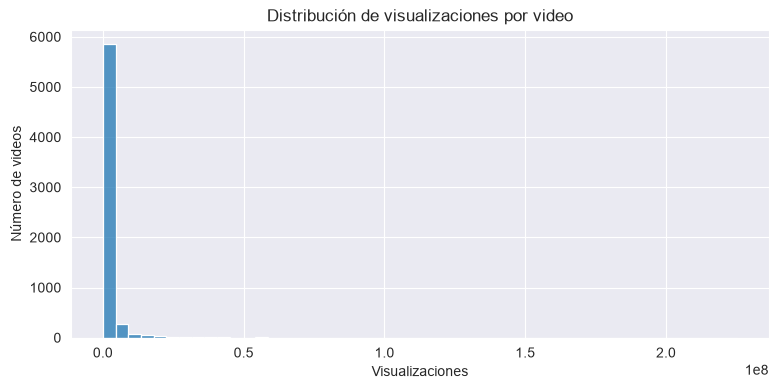

In [89]:
plt.figure(figsize=(9, 4))
sns.histplot(videos['views'], bins=50)

plt.title('Distribución de visualizaciones por video')
plt.xlabel('Visualizaciones')
plt.ylabel('Número de videos')
plt.show()

Aunque el promedio alcanza 1,96 millones de visualizaciones, la mitad de los videos no supera las 518 mil. El 25 % más popular supera los 1,47 millones. Esto permite identificar un segmento de alto desempeño que merece un análisis específico.

In [90]:
umbral = videos['views'].quantile(0.75)
videos_populares = videos[videos['views'] > umbral]
videos_populares

,video_id,views
2,-1Hm41N0dUs,2058516
5,-2aVkGcI7ZA,2390558
8,-35jibKqbEo,2425578
17,-7UzyXO-mzk,2620061
18,-7_ATlZ-zMc,3510260
...,...,...
6332,zi_6oaQyckM,7721222
6334,zkG4Xpz6t68,25142629
6335,zkrq7Kpd1so,1648886
6342,zuRd_Eneuk8,2163062


In [91]:
categorias_videos = df[['video_id', 'category_name']].drop_duplicates('video_id')

videos_populares = videos_populares.merge(
    categorias_videos,
    on='video_id',
    how='left'
)

videos_populares.head()

,video_id,views,category_name
0,-1Hm41N0dUs,2058516,Comedy
1,-2aVkGcI7ZA,2390558,Music
2,-35jibKqbEo,2425578,Music
3,-7UzyXO-mzk,2620061,Pets & Animals
4,-7_ATlZ-zMc,3510260,Sports


In [92]:
videos_populares['category_name'].value_counts()

category_name
Entertainment            424
Music                    356
Comedy                   177
Film & Animation         132
People & Blogs           124
Howto & Style             93
Sports                    73
Science & Technology      70
Gaming                    48
News & Politics           29
Education                 23
Pets & Animals            17
Autos & Vehicles          12
Travel & Events            8
Nonprofits & Activism      2
Name: count, dtype: int64

In [94]:
videos = videos.merge(categorias_videos, on='video_id', how='left')

videos['popular'] = videos['views'] > umbral

resultado = videos.groupby('category_name').agg(
    total_videos=('video_id', 'count'),
    videos_populares=('popular', 'sum'),
    porcentaje_popular=('popular', 'mean')
)

resultado['porcentaje_popular'] *= 100

resultado.sort_values('porcentaje_popular', ascending=False)

,total_videos,videos_populares,porcentaje_popular
category_name,,,
Gaming,103,48,46.601942
Music,799,356,44.555695
Film & Animation,318,132,41.509434
Comedy,547,177,32.358318
Entertainment,1619,424,26.189006
People & Blogs,498,124,24.899598
Science & Technology,380,70,18.421053
Autos & Vehicles,70,12,17.142857
Sports,451,73,16.186253


Los resultados muestran que Gaming (46,60 %), Music (44,56 %) y Film & Animation (41,51 %) son las categorías con mayor proporción de videos que superan el umbral de popularidad establecido. Por su parte, Entertainment reúne la mayor cantidad de videos populares (424), aunque proporcionalmente su desempeño es menor (26,19 %).

#### 2.2.2.¿Qué categorías de videos reciben mayores visualizaciones y likes?

In [96]:
videos_metricas = df.sort_values('views').drop_duplicates('video_id', keep='last')

In [97]:
resultado_metricas = videos_metricas.groupby('category_name')[['views', 'likes']].median()

resultado_metricas.sort_values('views', ascending=False).round(0)

,views,likes
category_name,,
Gaming,1316002.0,36922.0
Music,1096158.0,39940.0
Film & Animation,910970.0,11905.0
Comedy,790546.0,22900.0
Shows,765522.0,13675.0
Entertainment,606048.0,11733.0
Pets & Animals,434946.0,11601.0
Science & Technology,429830.0,11229.0
Howto & Style,426985.0,15910.0


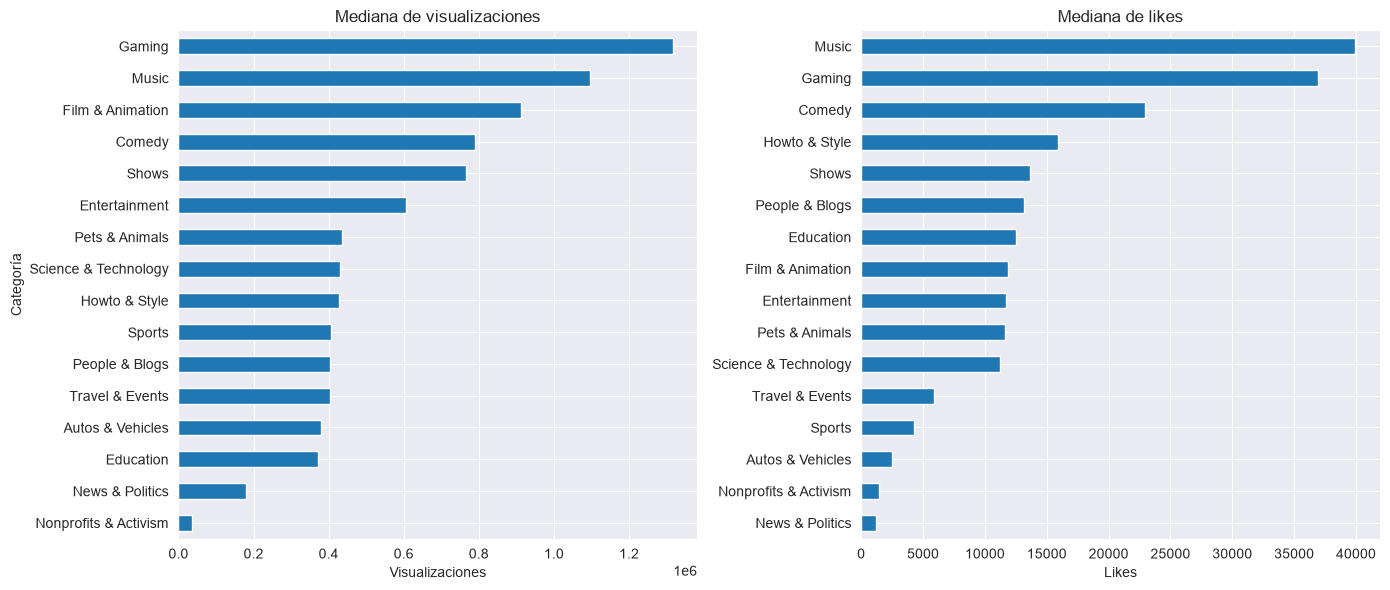

In [99]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

resultado_metricas.sort_values('views').plot(
    kind='barh', y='views', ax=ax[0], legend=False
)
ax[0].set_title('Mediana de visualizaciones')
ax[0].set_xlabel('Visualizaciones')
ax[0].set_ylabel('Categoría')

resultado_metricas.sort_values('likes').plot(
    kind='barh', y='likes', ax=ax[1], legend=False
)
ax[1].set_title('Mediana de likes')
ax[1].set_xlabel('Likes')
ax[1].set_ylabel('')

plt.tight_layout()
plt.show()

Music resulta especialmente interesante porque combina un alto alcance con una cantidad elevada de likes. Esto sugiere que puede ser una categoría relevante para explorar estrategias de contenido y promoción. Sin embargo, la elección de una categoría también debe considerar el público objetivo y el propósito de la campaña, ya que tener más visualizaciones no garantiza una mayor respuesta de la audiencia.

#### 2.2.2. ¿qué proporción de las visualizaciones se traduce en likes?

In [100]:
videos_metricas['tasa_likes'] = (
    videos_metricas['likes'] / videos_metricas['views'] * 100
)

In [101]:
(videos_metricas['views'] == 0).sum()

np.int64(0)

In [102]:
videos_metricas.groupby('category_name')['tasa_likes'].median().sort_values(
    ascending=False
).round(2)

category_name
Howto & Style            3.98
Music                    3.51
Education                3.33
People & Blogs           3.15
Comedy                   3.14
Pets & Animals           3.03
Gaming                   2.79
Science & Technology     2.45
Nonprofits & Activism    2.36
Film & Animation         2.05
Shows                    1.99
Entertainment            1.98
Travel & Events          1.78
Sports                   0.95
Autos & Vehicles         0.90
News & Politics          0.81
Name: tasa_likes, dtype: float64

In [104]:
tasa_categoria = videos_metricas.groupby('category_name')['tasa_likes'].median()
tasa_categoria = tasa_categoria.sort_values(ascending=False)

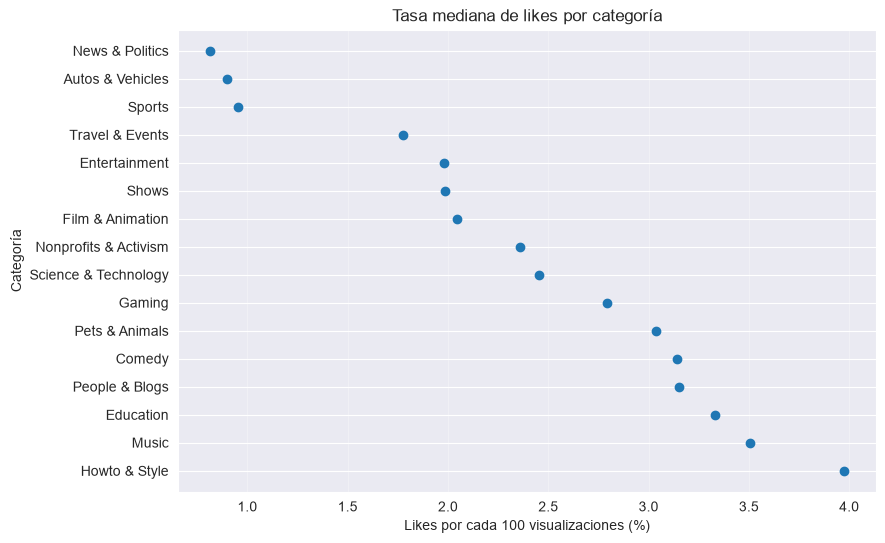

In [105]:
plt.figure(figsize=(9, 6))

plt.scatter(tasa_categoria.values, tasa_categoria.index)

plt.title('Tasa mediana de likes por categoría')
plt.xlabel('Likes por cada 100 visualizaciones (%)')
plt.ylabel('Categoría')
plt.grid(axis='x', alpha=0.3)

plt.show()

La categoría Howto & Style presenta la mayor tasa mediana de likes (3,98 por cada 100 visualizaciones), seguida de Music (3,51) y Education (3,33). Esto muestra que las categorías con mayor alcance no necesariamente son las que reciben más reacciones positivas en términos relativos. Para el negocio, Music resulta especialmente interesante porque combina un alto número de visualizaciones con una buena tasa de likes, mientras que Howto & Style y Education destacan por su respuesta relativa.

### 2.2.3. ¿La fecha o el momento de publicación influye en el desempeño de los videos?

In [109]:
df['publish_time'] = pd.to_datetime(df['publish_time'], utc=True)

In [110]:
videos_metricas['publish_time'] = pd.to_datetime(
    videos_metricas['publish_time'], utc=True
)

videos_metricas['dia_publicacion'] = videos_metricas['publish_time'].dt.day_name()

In [111]:
videos_metricas.groupby('dia_publicacion')['views'].median().sort_values(
    ascending=False
)

dia_publicacion
Saturday     570053.0
Thursday     565320.5
Friday       562298.0
Sunday       537443.0
Monday       502040.0
Wednesday    462063.0
Tuesday      451533.0
Name: views, dtype: float64

En los videos analizados, las publicaciones realizadas los sábados, jueves y viernes presentan un mayor número típico de visualizaciones. Esto sugiere que estos días podrían ser interesantes para explorar estrategias de publicación

In [113]:
videos_metricas.groupby('dia_publicacion')['views'].agg(
    cantidad='count',
    mediana='median'
).sort_values('mediana', ascending=False)

,cantidad,mediana
dia_publicacion,,
Saturday,547,570053.0
Thursday,1056,565320.5
Friday,1047,562298.0
Sunday,559,537443.0
Monday,985,502040.0
Wednesday,1097,462063.0
Tuesday,1060,451533.0


Los videos publicados los sábados, jueves y viernes presentan las mayores medianas de visualizaciones. Aunque el sábado ocupa el primer lugar, su diferencia respecto al jueves es pequeña. Estos días podrían considerarse para evaluar estrategias de publicación.

### 2.2.4. ¿Qué categorías de videos tardan menos tiempo en aparecer en tendencias?

In [119]:
df['publish_time'] = pd.to_datetime(df['publish_time'], utc=True)
df['trending_date'] = pd.to_datetime(df['trending_date'], utc=True)

In [120]:
primeras_tendencias = df.sort_values('trending_date').drop_duplicates('video_id')

In [121]:
primeras_tendencias['dias_tendencia'] = (
    primeras_tendencias['trending_date'] - primeras_tendencias['publish_time']
).dt.total_seconds() / 86400

In [122]:
primeras_tendencias = df.sort_values('trending_date').drop_duplicates('video_id')

In [123]:
primeras_tendencias['dias_tendencia'] = (
    primeras_tendencias['trending_date'] - primeras_tendencias['publish_time']
).dt.total_seconds() / 86400

In [124]:
(primeras_tendencias['dias_tendencia'] < 0).sum()

np.int64(119)

In [125]:
resultado_tiempo = primeras_tendencias.groupby('category_name')['dias_tendencia'].agg(
    cantidad='count',
    promedio='mean',
    mediana='median'
)

resultado_tiempo.sort_values('mediana').round(2)

,cantidad,promedio,mediana
category_name,,,
Gaming,103,40.71,0.91
Sports,451,19.54,0.93
Comedy,547,10.20,0.95
News & Politics,505,14.41,0.95
Music,799,22.19,1.00
Entertainment,1619,17.57,1.10
Shows,4,1.09,1.12
Howto & Style,595,4.70,1.12
People & Blogs,498,19.52,1.16


In [126]:
primeras_tendencias['dias_tendencia'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    6351.000000
mean       21.943379
std       209.965703
min        -0.541713
25%         0.457529
50%         1.102269
75%         2.115503
90%         3.968218
95%         5.317975
99%       526.378183
max      4214.649873
Name: dias_tendencia, dtype: float64

In [127]:
print('Tiempos negativos:',
      (primeras_tendencias['dias_tendencia'] < 0).sum())

print('Tiempos mayores a 365 días:',
      (primeras_tendencias['dias_tendencia'] > 365).sum())

Tiempos negativos: 119
Tiempos mayores a 365 días: 69


In [128]:
primeras_tendencias['dias_tendencia'] = (
    primeras_tendencias['trending_date'].dt.normalize()
    - primeras_tendencias['publish_time'].dt.normalize()
).dt.days

In [129]:
(primeras_tendencias['dias_tendencia'] < 0).sum()

np.int64(0)

In [130]:
resultado_tiempo = primeras_tendencias.groupby('category_name')['dias_tendencia'].agg(
    cantidad='count',
    promedio='mean',
    mediana='median'
)

resultado_tiempo.sort_values('mediana').round(2)

,cantidad,promedio,mediana
category_name,,,
Comedy,547,10.76,1.0
Gaming,103,41.33,1.0
Music,799,22.69,1.0
News & Politics,505,15.00,1.0
Sports,451,20.01,1.0
Education,250,61.80,2.0
Entertainment,1619,18.16,2.0
Autos & Vehicles,70,71.96,2.0
Howto & Style,595,5.32,2.0


Desde una perspectiva de negocio, los videos de la categoría Comedy suelen alcanzar tendencias rápidamente, con un tiempo mediano de 1 día. Sin embargo, el promedio de 10,76 días indica que algunos contenidos logran aparecer en tendencias mucho después de su publicación. Esto sugiere que, aunque es importante monitorear el desempeño durante los primeros días, también conviene dar seguimiento a contenidos antiguos que podrían ganar visibilidad posteriormente.

### 2.2.4. ¿Cuáles son los canales con más videos en tendencia y qué nivel de interacción generan por video en términos de visualizaciones y likes?

In [133]:
# Resumir los resultados por canal
resultado_canales = videos_metricas.groupby('channel_title').agg(
    cantidad_videos=('video_id', 'count'),
    mediana_vistas=('views', 'median'),
    mediana_likes=('likes', 'median'),
    mediana_tasa_likes=('tasa_likes', 'median')
)



In [134]:
top_canales = resultado_canales.sort_values(
    'cantidad_videos', ascending=False
).head(10)

top_canales.round(2)

,cantidad_videos,mediana_vistas,mediana_likes,mediana_tasa_likes
channel_title,,,,
ESPN,84,506190.5,3898.5,0.85
TheEllenShow,74,883050.0,16106.0,1.85
The Tonight Show Starring Jimmy Fallon,72,590906.0,10904.5,1.81
Jimmy Kimmel Live,70,874775.0,13191.0,1.56
The Late Show with Stephen Colbert,58,577808.0,6602.0,1.24
Netflix,58,433453.5,6930.0,1.78
NBA,55,293295.0,3503.0,1.27
CNN,52,327963.0,3093.5,0.85
Vox,47,655073.0,17500.0,2.68


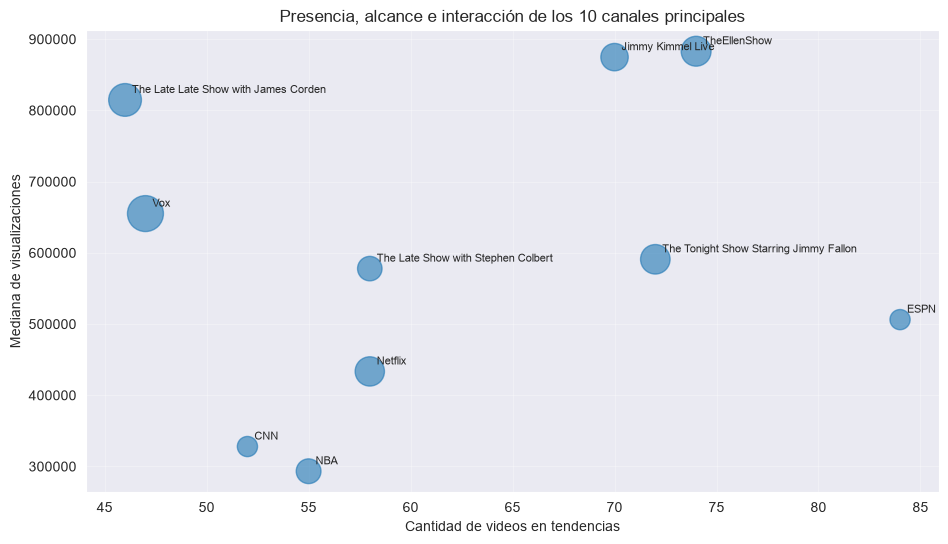

In [135]:
plt.figure(figsize=(11, 6))

plt.scatter(
    top_canales['cantidad_videos'],
    top_canales['mediana_vistas'],
    s=top_canales['mediana_tasa_likes'] * 250,
    alpha=0.6
)

for canal, fila in top_canales.iterrows():
    plt.annotate(
        canal,
        (fila['cantidad_videos'], fila['mediana_vistas']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=8
    )

plt.title('Presencia, alcance e interacción de los 10 canales principales')
plt.xlabel('Cantidad de videos en tendencias')
plt.ylabel('Mediana de visualizaciones')
plt.grid(alpha=0.3)
plt.show()

Una mayor presencia en tendencias no garantiza un mayor alcance ni una mejor interacción. ESPN lidera con 84 videos, pero alcanza una mediana de 506.191 visualizaciones y una tasa de likes del 0,85 %. En contraste, TheEllenShow, con 74 videos, registra 883.050 visualizaciones medianas, aproximadamente un 74 % más que ESPN. Por su parte, Vox, con apenas 47 videos, presenta la mayor tasa mediana de likes del grupo (2,68 %).

### 2.2.5. ¿Cuáles son los canales con más videos en tendencia y qué nivel de interacción generan por video en términos de visualizaciones y likes?

In [136]:
umbral = videos_metricas['views'].quantile(0.75)

videos_virales = videos_metricas[
    videos_metricas['views'] > umbral
].copy()

print('Videos seleccionados:', len(videos_virales))


Videos seleccionados: 1588


In [137]:
etiquetas = videos_virales['tags'].str.split('|').explode()

etiquetas = etiquetas.str.replace('"', '', regex=False).str.strip().str.lower()

etiquetas = etiquetas[~etiquetas.isin(['', '[none]'])]

top_etiquetas = etiquetas.value_counts().head(15)

top_etiquetas

tags
funny         202
comedy        181
pop            91
trailer        79
music          73
late night     66
humor          66
comedian       64
live           56
review         52
buzzfeed       52
official       52
2018           52
how to         51
video          49
Name: count, dtype: int64

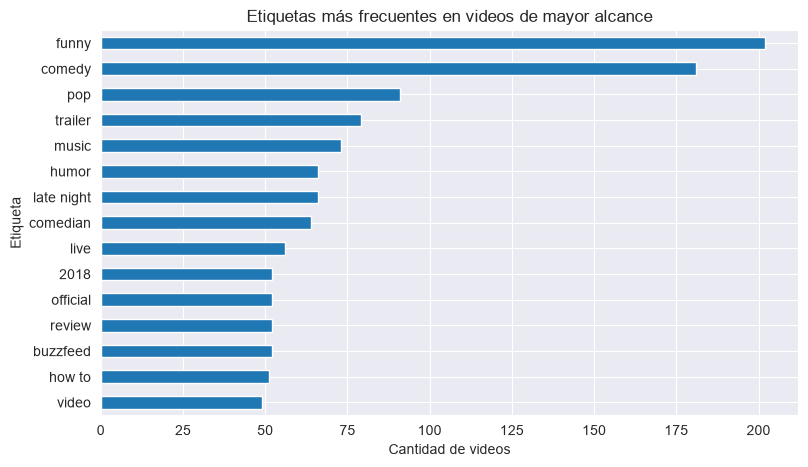

In [139]:
plt.figure(figsize=(9, 5))

top_etiquetas.sort_values().plot(kind='barh')

plt.title('Etiquetas más frecuentes en videos de mayor alcance')
plt.xlabel('Cantidad de videos')
plt.ylabel('Etiqueta')
plt.show()

Entre los videos de mayor alcance, las etiquetas más frecuentes son «funny» (aproximadamente 202 videos) y «comedy» (181 videos), seguidas de «pop» (91), «trailer» (79) y «music» (73). Esto evidencia una presencia destacada de contenidos asociados con el humor, el entretenimiento y la música dentro del 25 % de videos con más visualizaciones del conjunto analizado.

In [140]:
df.to_csv('../data/youtube_consolidado.csv', index=False)

## Conclusiones y recomendaciones

1. **Priorizar el alcance según la categoría.** *Gaming* (1,32 millones) y *Music* (1,10 millones) registran las mayores medianas de visualizaciones por video. Recomiendo explorar estas categorías para campañas de visibilidad, siempre que sus audiencias sean afines

2. **Probar publicaciones los sábados.** Los videos publicados ese día alcanzaron una mediana de **570.053 visualizaciones**, frente a **451.533 los martes**, una diferencia del 26 %. Recomiendo realizar pruebas durante varias semanas antes de establecer un día fijo de publicación.

3. **Monitorear los videos desde su publicación.** En *Comedy*, *Music* y *Sports*, la mediana hasta la primera aparición en tendencias fue de **1 día**. Recomiendo revisar el desempeño durante las primeras 48 horas y mantener un seguimiento posterior, ya que algunos contenidos aparecen en tendencias mucho después.

4. **Preseleccionar colaboradores según el objetivo.** *TheEllenShow* registra **883.050 visualizaciones medianas** por video, mientras que *Vox* presenta una tasa mediana de likes del **2,68 %**, frente al **0,85 % de ESPN**. Recomiendo evaluar el primero para campañas de alcance y el segundo para campañas de interacción, verificando previamente audiencia, afinidad y costos.

5. **Experimentar con contenidos de entretenimiento.** Las etiquetas *funny* y *comedy* aparecen aproximadamente en **202 y 181 videos**, respectivamente, dentro del grupo de mayor alcance. Recomiendo probar contenidos tecnológicos con elementos de humor y comparar sus resultados con formatos tradicionales.

**Recomendación final:** realizar una prueba piloto de contenidos y posibles colaboraciones, evaluando visualizaciones, tasa de likes y costo por resultado. Los hallazgos permiten priorizar opciones, pero no garantizan que estas estrategias produzcan el mismo desempeño en nuevos videos.